In [ ]:
pip install tensorflow scikit-learn matplotlib kaggle pillow

In [ ]:
!kaggle datasets download -d asdasdasasdas/garbage-classification
!unzip garbage-classification.zip -d waste_data

Streaming output truncated to the last 5000 lines.
  inflating: waste_data/Garbage classification/Garbage classification/cardboard/cardboard152.jpg  
  inflating: waste_data/Garbage classification/Garbage classification/cardboard/cardboard153.jpg  
  inflating: waste_data/Garbage classification/Garbage classification/cardboard/cardboard154.jpg  
  inflating: waste_data/Garbage classification/Garbage classification/cardboard/cardboard155.jpg  
  inflating: waste_data/Garbage classification/Garbage classification/cardboard/cardboard156.jpg  
  inflating: waste_data/Garbage classification/Garbage classification/cardboard/cardboard157.jpg  
  inflating: waste_data/Garbage classification/Garbage classification/cardboard/cardboard158.jpg  
  inflating: waste_data/Garbage classification/Garbage classification/cardboard/cardboard159.jpg  
  inflating: waste_data/Garbage classification/Garbage classification/cardboard/cardboard16.jpg  
  inflating: waste_data/Garbage classification/Garbage clas

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array

print("TF Version:", tf.__version__)

TF Version: 2.20.0


In [ ]:
# ── STEP 3 : CONFIG ──────────────────────────────────────────
DATA_DIR   = "waste_data/Garbage classification/Garbage classification"
IMG_SIZE   = 128        # resize all images to 128x128
BATCH_SIZE = 32
EPOCHS     = 10

In [ ]:
# ── STEP 4 : LOAD DATA ───────────────────────────────────────
# 80% train, 20% validation split
train_gen = ImageDataGenerator(rescale=1./255, validation_split=0.2,
                               horizontal_flip=True, zoom_range=0.2)

train_data = train_gen.flow_from_directory(
    DATA_DIR, target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE, class_mode='categorical',
    subset='training', seed=42)

val_data = train_gen.flow_from_directory(
    DATA_DIR, target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE, class_mode='categorical',
    subset='validation', seed=42)

CLASS_NAMES = list(train_data.class_indices.keys())
NUM_CLASSES = len(CLASS_NAMES)
print("Classes:", CLASS_NAMES)

Found 2024 images belonging to 6 classes.
Found 503 images belonging to 6 classes.
Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


In [ ]:
# ── STEP 5 : BUILD CNN MODEL ─────────────────────────────────
model = models.Sequential([
    # Block 1
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.MaxPooling2D(2,2),

    # Block 2
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    # Block 3
    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    # Classifier Head
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(NUM_CLASSES, activation='softmax')
])

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,414 (12.61 MB)

 Trainable params: 3,305,414 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ── STEP 6 : COMPILE ─────────────────────────────────────────
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [ ]:
history = model.fit(train_data, validation_data=val_data, epochs=EPOCHS)

Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 87s 1s/step - accuracy: 0.2950 - loss: 1.6576 - val_accuracy: 0.3300 - val_loss: 1.5737
Epoch 2/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 79s 1s/step - accuracy: 0.4056 - loss: 1.4207 - val_accuracy: 0.3877 - val_loss: 1.4498
Epoch 3/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 79s 1s/step - accuracy: 0.4812 - loss: 1.3092 - val_accuracy: 0.3996 - val_loss: 1.4105
Epoch 4/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 88s 1s/step - accuracy: 0.5015 - loss: 1.2563 - val_accuracy: 0.4592 - val_loss: 1.3431
Epoch 5/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 79s 1s/step - accuracy: 0.5400 - loss: 1.1862 - val_accuracy: 0.4791 - val_loss: 1.3500
Epoch 6/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 79s 1s/step - accuracy: 0.5548 - loss: 1.1626 - val_accuracy: 0.4672 - val_loss: 1.3947
Epoch 7/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 79s 1s/step - accuracy: 0.5726 - loss: 1.1094 - val_accuracy: 0.4771 - val_loss: 1.3470
Epoch 8/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 78s 1s/step - accuracy: 0.6028 - loss: 1.0850 - val_accuracy: 0.4911 - val_loss:

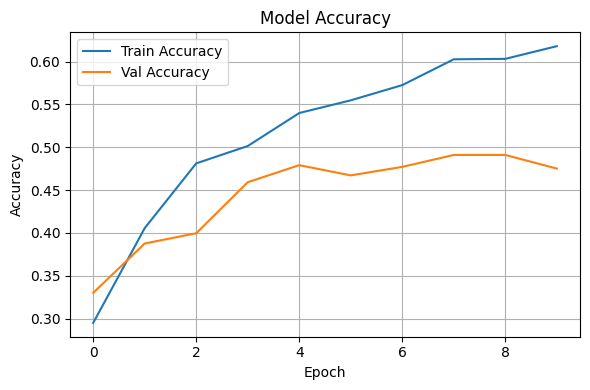

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(history.history['accuracy'],     label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("accuracy.png", dpi=150)
plt.show()

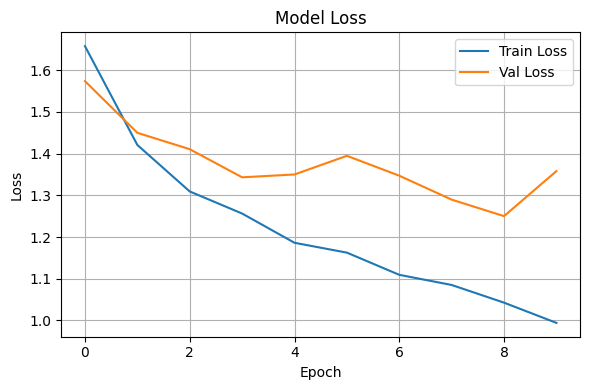

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(history.history['loss'],     label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("loss.png", dpi=150)
plt.show()

In [ ]:
# Overall Model Accuracy
loss, accuracy = model.evaluate(val_data, verbose=1)

print("\n==============================")
print(f"  Loss     : {loss:.4f}")
print(f"  Accuracy : {accuracy * 100:.2f}%")
print("==============================")

16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 473ms/step - accuracy: 0.4652 - loss: 1.3580

  Loss     : 1.3580
  Accuracy : 46.52%


In [ ]:
# ── STEP 9 : EVALUATE
val_data.reset()
y_pred  = np.argmax(model.predict(val_data), axis=1)
y_true  = val_data.classes

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))



16/16 ━━━━━━━━━━━━━━━━━━━━ 7s 392ms/step

Classification Report:
              precision    recall  f1-score   support

   cardboard       0.22      0.11      0.15        80
       glass       0.19      0.22      0.21       100
       metal       0.14      0.06      0.08        82
       paper       0.26      0.50      0.34       118
     plastic       0.24      0.20      0.22        96
       trash       0.00      0.00      0.00        27

    accuracy                           0.23       503
   macro avg       0.17      0.18      0.17       503
weighted avg       0.20      0.23      0.20       503



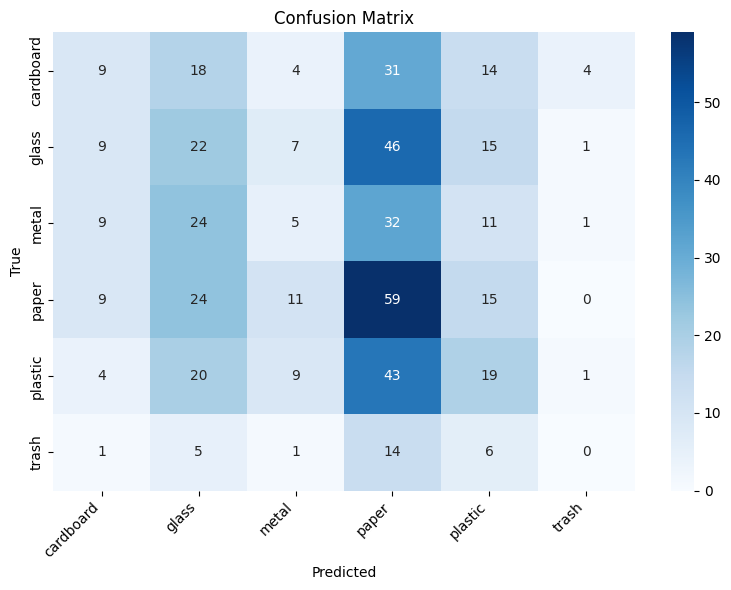

In [ ]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title("Confusion Matrix"); plt.ylabel("True"); plt.xlabel("Predicted")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

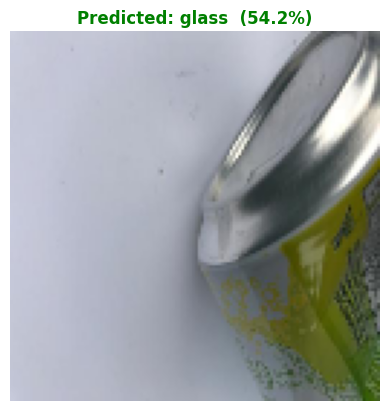

Predicted: glass  (54.2%)


In [ ]:
# ── TEST ON SAMPLE IMAGES ─────────────────────────────────────

img_path = "/content/waste_data/Garbage classification/Garbage classification/metal/metal10.jpg"

img  = load_img(img_path, target_size=(IMG_SIZE, IMG_SIZE))
arr  = img_to_array(img) / 255.0
pred = model.predict(np.expand_dims(arr, 0), verbose=0)[0]
cls  = CLASS_NAMES[np.argmax(pred)]
conf = np.max(pred) * 100

plt.imshow(img)
plt.axis('off')
plt.title(f"Predicted: {cls}  ({conf:.1f}%)", fontsize=12, color='green', fontweight='bold')
plt.show()

print(f"Predicted: {cls}  ({conf:.1f}%)")

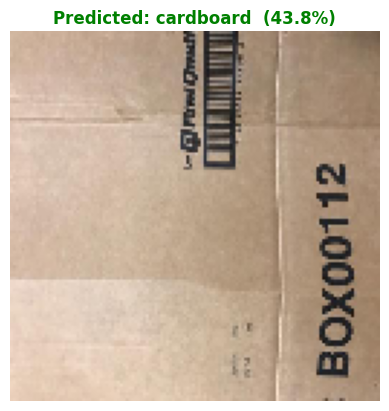

Predicted: cardboard  (43.8%)


In [ ]:
# ── TEST ON SAMPLE IMAGES ─────────────────────────────────────

img_path = "/content/waste_data/Garbage classification/Garbage classification/cardboard/cardboard10.jpg"

img  = load_img(img_path, target_size=(IMG_SIZE, IMG_SIZE))
arr  = img_to_array(img) / 255.0
pred = model.predict(np.expand_dims(arr, 0), verbose=0)[0]
cls  = CLASS_NAMES[np.argmax(pred)]
conf = np.max(pred) * 100

plt.imshow(img)
plt.axis('off')
plt.title(f"Predicted: {cls}  ({conf:.1f}%)", fontsize=12, color='green', fontweight='bold')
plt.show()

print(f"Predicted: {cls}  ({conf:.1f}%)")

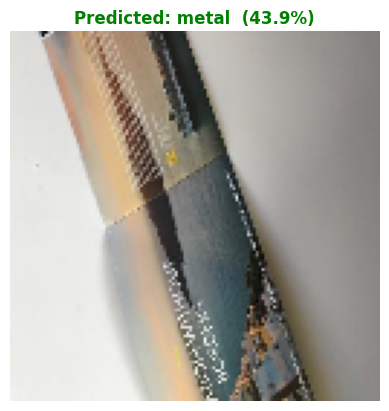

Predicted: metal  (43.9%)


In [ ]:
# ── TEST ON SAMPLE IMAGES ─────────────────────────────────────

img_path = "/content/waste_data/Garbage classification/Garbage classification/paper/paper102.jpg"

img  = load_img(img_path, target_size=(IMG_SIZE, IMG_SIZE))
arr  = img_to_array(img) / 255.0
pred = model.predict(np.expand_dims(arr, 0), verbose=0)[0]
cls  = CLASS_NAMES[np.argmax(pred)]
conf = np.max(pred) * 100

plt.imshow(img)
plt.axis('off')
plt.title(f"Predicted: {cls}  ({conf:.1f}%)", fontsize=12, color='green', fontweight='bold')
plt.show()

print(f"Predicted: {cls}  ({conf:.1f}%)")

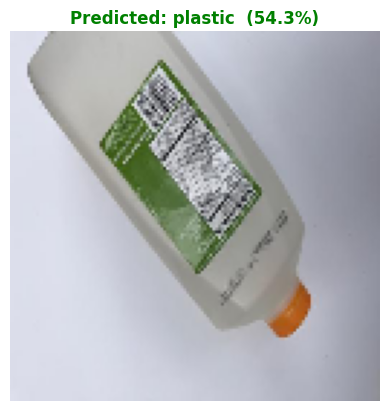

Predicted: plastic  (54.3%)


In [ ]:
# ── TEST ON SAMPLE IMAGES ─────────────────────────────────────

img_path = "/content/waste_data/Garbage classification/Garbage classification/plastic/plastic101.jpg"

img  = load_img(img_path, target_size=(IMG_SIZE, IMG_SIZE))
arr  = img_to_array(img) / 255.0
pred = model.predict(np.expand_dims(arr, 0), verbose=0)[0]
cls  = CLASS_NAMES[np.argmax(pred)]
conf = np.max(pred) * 100

plt.imshow(img)
plt.axis('off')
plt.title(f"Predicted: {cls}  ({conf:.1f}%)", fontsize=12, color='green', fontweight='bold')
plt.show()

print(f"Predicted: {cls}  ({conf:.1f}%)")

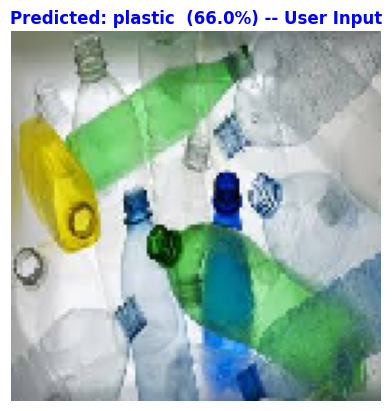

Predicted: plastic  (66.0%) -- User Input


In [ ]:
user_img_path = "/content/bottle.jpg" # @param {type:"string"}

# Load and preprocess the user's image
user_img = load_img(user_img_path, target_size=(IMG_SIZE, IMG_SIZE))
user_arr = img_to_array(user_img) / 255.0

# Expand dimensions to match model input shape
user_pred_array = model.predict(np.expand_dims(user_arr, 0), verbose=0)[0]

# Get predicted class and confidence
user_cls  = CLASS_NAMES[np.argmax(user_pred_array)]
user_conf = np.max(user_pred_array) * 100

# Display the image with prediction
plt.imshow(user_img)
plt.axis('off')
plt.title(f"Predicted: {user_cls}  ({user_conf:.1f}%) -- User Input", fontsize=12, color='blue', fontweight='bold')
plt.show()

print(f"Predicted: {user_cls}  ({user_conf:.1f}%) -- User Input")